# Бандиты по компонентам оффера на данных Starbucks

Эксперименты к статье «Персонализация маркетинговых коммуникаций…». Подход Aampe: сообщение — сочетание
критериев (тип оффера, порог, срок, каналы, слот времени); на каждый критерий свои веса, сочетание оценивается
суммой логитов, исследование — сэмплированием Томпсона.

1. **Данные.** Udacity / Starbucks rewards (симуляция Starbucks): 17 000 клиентов, 6 волн рассылки, в каждой ~75%
   клиентов получают один из 10 офферов случайно, ~25% — ничего. Награда — покупка за 72 ч после волны.
2. **Replay на логах.** Выбор среди 10 реальных офферов; несмещённая офлайн-оценка (Li et al., 2011).
3. **Полусинтетическая среда.** Отклик подогнан по данным, добавлен критерий «слот времени» с известным эффектом;
   288 сочетаний, считаем сожаление относительно оракула и прирост к «без оффера».

Код алгоритмов — `sblab.py`. Данные — `data/` (Kaggle `blacktile/starbucks-app-customer-reward-program-data`).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

from sblab import (CTX_NAMES, CriterionBeta, DisjointLogisticTS, FlatBeta, LabelLogisticTS, RandomPolicy,
                   TrueEnv, factorial_actions, load_data, logit, portfolio_actions, replay, simulate)

FIG = Path("../figures"); FIG.mkdir(exist_ok=True)
RESULTS = {}

# Цвет закреплён за политикой (не за рангом); в печати различаем ещё и типом линии
STYLE = {
    "Случайная":                          dict(color="#898989", ls=":"),
    "Beta на сочетание":                  dict(color="#2a78d6", ls="--"),
    "Бандит на критерий":                 dict(color="#eb6834", ls="-"),
    "Логистика по компонентам":           dict(color="#1baf7a", ls="-."),
    "Логистика по компонентам + контекст": dict(color="#6250d6", ls="-"),
    "Логистика на сочетание + контекст":  dict(color="#e87ba4", ls="--"),
}
plt.rcParams.update({"font.size": 8, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6,
                     "lines.linewidth": 1.6, "figure.dpi": 150, "savefig.bbox": "tight"})

## 1. Данные: офферы, отклик и проверка случайности рассылки

In [2]:
po, users, waves = load_data("data")
port = portfolio_actions(po)
X = users[CTX_NAMES].to_numpy()

def rate_ci(y):
    p = y.mean(); return p, 1.96 * np.sqrt(p * (1 - p) / len(y))

p0, _ = rate_ci(waves[waves.offer < 0].buy)
rows = []
for i, r in po.iterrows():
    y = waves[waves.offer == i].buy
    p, h = rate_ci(y)
    rows.append(dict(offer=i, тип=r.offer_type, награда=r.reward, порог=r.difficulty, срок=r.duration,
                     каналы=",".join(sorted(r.channels)), n=len(y), покупка_72ч=round(p, 3),
                     прирост=round(p - p0, 3), ci95=round(h, 3)))
offers = pd.DataFrame(rows).sort_values("покупка_72ч", ascending=False)
n0 = (waves.offer < 0).sum()
print(f"без оффера: n={n0}, покупка за 72 ч = {p0:.3f}")
offers

без оффера: n=25723, покупка за 72 ч = 0.429


,offer,тип,награда,порог,срок,каналы,n,покупка_72ч,прирост,ci95
6,6,discount,2,10,10,"email,mobile,social,web",7597,0.649,0.221,0.011
1,1,bogo,10,10,5,"email,mobile,social,web",7593,0.642,0.214,0.011
5,5,discount,3,7,7,"email,mobile,social,web",7646,0.639,0.210,0.011
8,8,bogo,5,5,5,"email,mobile,social,web",7571,0.632,0.203,0.011
0,0,bogo,10,10,7,"email,mobile,social",7658,0.610,0.182,0.011
7,7,informational,0,0,3,"email,mobile,social",7618,0.595,0.167,0.011
3,3,bogo,5,5,7,"email,mobile,web",7677,0.518,0.089,0.011
2,2,informational,0,0,4,"email,mobile,web",7617,0.511,0.083,0.011
9,9,discount,2,10,7,"email,mobile,web",7632,0.509,0.080,0.011
4,4,discount,5,20,10,"email,web",7668,0.471,0.043,0.011


In [3]:
# Случайность рассылки: оффер (включая «без оффера») не зависит от признаков клиента
m = waves.merge(users, left_on="uid", right_index=True)
m["возраст"] = pd.cut(m.age, [-9, -1, 0, 1, 9]).astype(str)
m["доход"] = pd.cut(m.income, [-9, -0.7, 0, 0.7, 9]).astype(str)
m["пол"] = np.select([m.female == 1, m.male == 1, m.no_profile == 1], ["F", "M", "нет"], "O")
balance = {c: chi2_contingency(pd.crosstab(m.offer, m[c]))[1] for c in ["пол", "возраст", "доход"]}
print("p-value χ² (оффер × признак):", {k: round(v, 3) for k, v in balance.items()})
RESULTS["data"] = dict(n_users=len(users), n_waves=int(waves.wave.nunique()), n_offer_events=int((waves.offer >= 0).sum()),
                       n_none=int(n0), p_none=float(p0), offers=offers.to_dict("records"),
                       balance_p={k: float(v) for k, v in balance.items()})

p-value χ² (оффер × признак): {'пол': np.float64(0.843), 'возраст': np.float64(0.7), 'доход': np.float64(0.642)}


## 2. Replay на реальных логах: выбор среди 10 офферов

Условно на факт отправки оффер выбирался равномерно (1/10), поэтому replay даёт несмещённую оценку
средней награды политики. Каждая политика проходит логи в случайном порядке 30 раз.

In [4]:
off = waves[waves.offer >= 0]
Xo, ao, yo = X[off.uid.to_numpy()], off.offer.to_numpy(), off.buy.to_numpy(float)
b0 = logit(yo.mean())   # априорное среднее свободного члена — средний отклик на оффер

def replay_policies():
    return [RandomPolicy(port), FlatBeta(port), CriterionBeta(port),
            LabelLogisticTS(port, len(CTX_NAMES), contextual=False, b0=b0),
            LabelLogisticTS(port, len(CTX_NAMES), contextual=True, b0=b0),
            DisjointLogisticTS(port, len(CTX_NAMES), b0=b0)]

SEEDS, N_CURVE = 30, 7000
runs = {}
for seed in range(SEEDS):
    for pol in replay_policies():
        r = replay(pol, Xo, ao, yo, np.random.default_rng(seed))
        runs.setdefault(pol.label, []).append(r[:N_CURVE])

In [5]:
def mean_ci(v):
    v = np.asarray(v); return v.mean(), 1.96 * v.std(ddof=1) / np.sqrt(len(v))

best_offer = offers.покупка_72ч.max()
rows = []
for lab, rs in runs.items():
    R = np.vstack(rs)
    first, last, total = R[:, :1000].mean(1), R[:, -2000:].mean(1), R.mean(1)
    rows.append(dict(политика=lab, первые_1000=mean_ci(first)[0], последние_2000=mean_ci(last)[0],
                     все=mean_ci(total)[0], ci95=mean_ci(total)[1], прирост_к_без_оффера=mean_ci(total)[0] - p0))
replay_tab = pd.DataFrame(rows).round(4)
print(f"лучший оффер в среднем по логам: {best_offer:.3f}; без оффера: {p0:.3f}")
RESULTS["replay"] = dict(seeds=SEEDS, n_curve=N_CURVE, best_offer=float(best_offer), table=replay_tab.to_dict("records"))
replay_tab

лучший оффер в среднем по логам: 0.649; без оффера: 0.429


,политика,первые_1000,последние_2000,все,ci95,прирост_к_без_оффера
0,Случайная,0.5872,0.5767,0.5785,0.0018,0.1498
1,Beta на сочетание,0.6163,0.6370,0.6307,0.0018,0.2019
2,Бандит на критерий,0.6208,0.6340,0.6313,0.0043,0.2025
3,Логистика по компонентам,0.6100,0.6332,0.6299,0.0019,0.2012
4,Логистика по компонентам + контекст,0.6072,0.6344,0.6244,0.0020,0.1957
5,Логистика на сочетание + контекст,0.6015,0.6312,0.6215,0.0022,0.1928


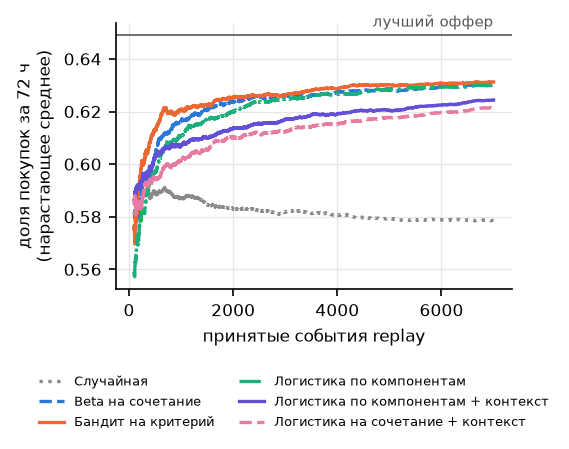

In [6]:
fig, ax = plt.subplots(figsize=(3.4, 2.3))
n = np.arange(1, N_CURVE + 1)
for lab, rs in runs.items():
    curve = (np.cumsum(np.vstack(rs), axis=1) / n).mean(0)
    ax.plot(n[100:], curve[100:], label=lab, **STYLE[lab])
ax.axhline(best_offer, color="#555", lw=0.8)
ax.text(N_CURVE, best_offer + 0.002, "лучший оффер", ha="right", va="bottom", fontsize=7, color="#555")
ax.set_xlabel("принятые события replay"); ax.set_ylabel("доля покупок за 72 ч\n(нарастающее среднее)")
ax.legend(fontsize=6, frameon=False, loc="upper center", bbox_to_anchor=(0.45, -0.28), ncol=2)
fig.savefig(FIG / "replay.pdf"); plt.show()

## 3. Полусинтетическая среда: 288 сочетаний

Истинный отклик — логистика `клиент × компоненты`, подогнанная по всем волнам (в том числе без оффера).
Критерий «слот» (утро / день / вечер / ночь) в данных отсутствует — его эффект задан симулятором: сдвиг на слот
и наклон по возрасту (молодым лучше вечер, старшим — утро). Каждый день 500 случайных клиентов, обновление в конце дня.

In [7]:
env = TrueEnv(po, users, waves)
fa = factorial_actions(with_slot=True)
fa72 = factorial_actions(with_slot=False)
eff = pd.DataFrame({"признак": env.feat_names, "вес": env.w, "sd": env.w_sd})
show = eff[eff.признак.isin(port.feat_names) | eff.признак.str.startswith("sent")].round(3)
P = env.prob(X, fa)
print(f"сочетаний: {fa.n}; средний отклик сочетаний {P.mean(0).min():.3f}…{P.mean(0).max():.3f}; "
      f"оракул {P.max(1).mean():.3f}; без оффера {env.prob_none(X).mean():.3f}")
RESULTS["env"] = dict(n_actions=fa.n, p_min=float(P.mean(0).min()), p_max=float(P.mean(0).max()),
                      p_oracle=float(P.max(1).mean()), p_none=float(env.prob_none(X).mean()),
                      oracle_distinct=int((np.bincount(P.argmax(1), minlength=fa.n) > 0).sum()),
                      slot_base=env.SLOT_BASE.tolist(), slot_age=env.SLOT_AGE.tolist())
show

сочетаний: 288; средний отклик сочетаний 0.284…0.706; оракул 0.738; без оффера 0.429


,признак,вес,sd
7,sent×const,0.273,0.271
8,sent×no_profile,-0.490,0.289
9,sent×female,-0.412,0.278
10,sent×male,-0.329,0.276
11,sent×age,0.001,0.047
12,sent×income,-0.071,0.048
13,sent×tenure,-0.178,0.046
14,type=bogo,0.095,0.229
15,type=discount,0.059,0.324
16,threshold=hard,0.004,0.163


In [8]:
DAYS, PER_DAY, SIM_SEEDS = 60, 500, 20

def sim_policies(acts):
    return [RandomPolicy(acts), FlatBeta(acts), CriterionBeta(acts),
            LabelLogisticTS(acts, len(CTX_NAMES), contextual=False, b0=b0),
            LabelLogisticTS(acts, len(CTX_NAMES), contextual=True, b0=b0)]

def run_sim(acts, per_day=PER_DAY):
    out = {}
    for seed in range(SIM_SEEDS):
        for pol in sim_policies(acts):
            reg, val, up = simulate(pol, env, acts, X, DAYS, per_day, np.random.default_rng(100 + seed))
            out.setdefault(pol.label, []).append((reg, val, up))
    return out

sims = {"288": run_sim(fa), "72": run_sim(fa72)}

In [9]:
def sim_table(out, acts):
    Pm = env.prob(X, acts)
    up_oracle = (Pm.max(1) - env.prob_none(X)).mean()
    rows = []
    for lab, rs in out.items():
        reg = np.array([r[0].sum() for r in rs]) / PER_DAY            # сожаление на клиента-день, сумма за горизонт
        up_last = np.array([r[2][-10:].mean() for r in rs])
        rows.append(dict(политика=lab, сожаление=mean_ci(reg)[0], ci95=mean_ci(reg)[1],
                         прирост_последние_10_дней=up_last.mean(), доля_прироста_оракула=up_last.mean() / up_oracle))
    return pd.DataFrame(rows).round(4), up_oracle

tabs = {}
for k, acts in [("288", fa), ("72", fa72)]:
    tabs[k], upo = sim_table(sims[k], acts)
    RESULTS[f"sim_{k}"] = dict(days=DAYS, per_day=PER_DAY, seeds=SIM_SEEDS, uplift_oracle=float(upo),
                               table=tabs[k].to_dict("records"))
    print(f"--- {k} сочетаний, прирост оракула к «без оффера» = {upo:.3f}"); display(tabs[k])

--- 288 сочетаний, прирост оракула к «без оффера» = 0.309


,политика,сожаление,ci95,прирост_последние_10_дней,доля_прироста_оракула
0,Случайная,13.0727,0.0167,0.0903,0.2924
1,Beta на сочетание,7.5869,0.0477,0.2123,0.6872
2,Бандит на критерий,2.7986,0.2866,0.2669,0.8638
3,Логистика по компонентам,2.7935,0.0761,0.2719,0.8800
4,Логистика по компонентам + контекст,1.9159,0.1040,0.2935,0.9501


--- 72 сочетаний, прирост оракула к «без оффера» = 0.242


,политика,сожаление,ci95,прирост_последние_10_дней,доля_прироста_оракула
0,Случайная,8.8407,0.0177,0.0935,0.3865
1,Beta на сочетание,2.9640,0.0512,0.2122,0.8772
2,Бандит на критерий,1.4699,0.3526,0.2210,0.9136
3,Логистика по компонентам,1.2379,0.1234,0.2282,0.9435
4,Логистика по компонентам + контекст,1.3838,0.0623,0.2296,0.9493


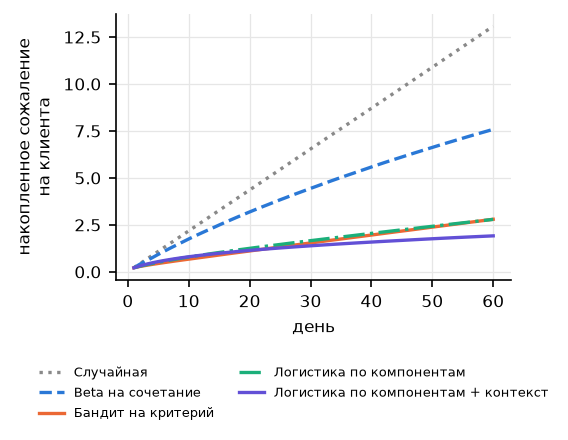

In [10]:
fig, ax = plt.subplots(figsize=(3.4, 2.3))
days = np.arange(1, DAYS + 1)
for lab, rs in sims["288"].items():
    cum = np.mean([np.cumsum(r[0]) / PER_DAY for r in rs], axis=0)
    ax.plot(days, cum, label=lab, **STYLE[lab])
ax.set_xlabel("день"); ax.set_ylabel("накопленное сожаление\nна клиента")
ax.legend(fontsize=6, frameon=False, loc="upper center", bbox_to_anchor=(0.45, -0.28), ncol=2)
fig.savefig(FIG / "sim_regret.pdf"); plt.show()

## 4. Что выучила контекстная модель: эффект слота по возрасту

Сравниваем апостериорное среднее эффекта слота (относительно утра) у младших и старших клиентов с истиной симулятора.

In [11]:
pol = LabelLogisticTS(fa, len(CTX_NAMES), contextual=True, b0=b0)
simulate(pol, env, fa, X, DAYS, PER_DAY, np.random.default_rng(7))
slot_cols = [fa.feat_names.index(f"slot={s}") for s in ["day", "evening", "night"]]
age = X[:, CTX_NAMES.index("age")]
rows = []
for name, mask in [("моложе (age_z < −0.7)", (age < -0.7) & (X[:, 1] == 0)), ("старше (age_z > 0.7)", age > 0.7)]:
    est = pol.mean_effects(X[mask])[:, slot_cols].mean(0)
    a = age[mask].mean()
    true = env.SLOT_BASE[1:] + a * env.SLOT_AGE[1:] - (env.SLOT_BASE[0] + a * env.SLOT_AGE[0])
    rows.append(dict(группа=name, **{f"{s}: оценка": e for s, e in zip(["день", "вечер", "ночь"], est)},
                     **{f"{s}: истина": t for s, t in zip(["день", "вечер", "ночь"], true)}))
slot_tab = pd.DataFrame(rows).round(2)
RESULTS["slot_recovery"] = slot_tab.to_dict("records")
slot_tab

,группа,день: оценка,вечер: оценка,ночь: оценка,день: истина,вечер: истина,ночь: истина
0,моложе (age_z < −0.7),0.41,1.09,0.15,0.50,1.05,0.13
1,старше (age_z > 0.7),-0.19,-0.46,-0.98,-0.28,-0.50,-0.90


In [12]:
Path("results.json").write_text(json.dumps(RESULTS, ensure_ascii=False, indent=1, default=float))
print("сохранено: results.json, ../figures/replay.pdf, ../figures/sim_regret.pdf")

сохранено: results.json, ../figures/replay.pdf, ../figures/sim_regret.pdf
